## Partie 1  - Numériques pour équations différentielles ordinaires  (EDO)

### ATTENTION: 
> #### L'exercice 1 est à faire entèrement sur copies
> #### L'exercice 2 contient une partie théorique à faire sur copies.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import matplotlib.pyplot as plt

On se propose dans cette partie quelques schémas numériques à **un pas** pour la résolution 
de l'équation différentielle ordinaire : 
\begin{equation}
(EDO)\quad \left\{
\begin{array}{rcl}
x'(t)  &=& f(t, x(t)), \quad t \in ]t_0, t_0 + T[,\\
x(t_0) &=& x^0
\end{array}
\right.
\end{equation}
où  $f \in C^r ([t_0, t_0 + T]\times \mathbb{R}; \mathbb{R}), x^0 \in \mathbb{R}$ et où $T$ est un réel strictement positif et $t_0\in \mathbb{R}$ (les valeurs de $r, t_0, T, x^0$ seront précisées dans chaque exercice).

Pour résoudre numériquement ce problème de Cauchy, on se donne un entier $N \in \mathbb{N}^*$, 
et on considère une subdivision uniforme $t_0 < t_1 < \ldots < t_N = (t_0 + T)$ de $[t_0, t_0 + T]$
de pas $\Delta t = \frac{T}{N}$, définie par $t_n = t_0 + n\, \Delta t \quad (0\leq n \leq N)$. 
Puis on construit la suite $(x_n)_{0\leq n\leq N}$ telle que $x_n$ soit une valeur approchée de $x(t_n)$ pour tout $ n \in \{0, \ldots, N\}$, via une schéma numérique à un pas dont une forme générale lorsqu'il est **explicite** est donnée par : 

\begin{equation}
(S)\quad \left\{
\begin{array}{rcl}
x_{n+1}  &=& x_n + \Delta t \,\Phi(t_n, x_n, \Delta t), \quad n = 0,\ldots, N-1,\\
x_0 &=& x^0;
\end{array}
\right.
\end{equation}
où $\Phi(\cdot,\cdot,\cdot): \mathbb{R}\times\mathbb{R}\times\mathbb{R} \rightarrow \mathbb{R}$ est une fonction à trois variables dont on devra péciser l'expression (i.e $\Phi(t, y, \Delta t)$) pour chaque schéma numérique (en fonction de $f $).



## Exercice 1 : Question de cours ( A faire entièrement sur copie)

#### Question 1-1 : Exemple
Donnez l'expression de $\Phi(t, y, \Delta t)$ dans le cas du schéma d'Euler explicite

#### Question 1-2 : Analyse 
On suppose que $f$ est Lipschitzienne en espace de constante $L$ c'est-à-dire : 
$|f(t,y) - f(t,z)| \leq L |y - z| \quad \forall t,y,z \in \mathbb{R}$.

> Montrer en vous servant de la fonction $\Phi(t, y, \Delta t)$ que le schéma d'Euler explicite est convegent d'ordre 1.



## Exercice 2 : Théta schéma dans un cadre explicitable 


Dans cette partie on considère l'équation différentielle ci-dessus avec 
$ $f(t,x) = \frac{ x + e^{\frac{\pi}{3}}}{t^2 + 1}$ $

Et on considère le schéma numérique suivant appelé $\theta$-$schéma$: 

\begin{equation}
(S_{\theta})\quad \left\{
\begin{array}{rcl}
x_{n+1}  &=& x_n + \Delta t \Big((1 - \theta) f(t_n, x_n) + \theta f(t_{n+1}, x_{n+1}) \Big), \quad n = 0,\ldots, N-1,\\
x_0 &=& x^0;
\end{array}
\right.
\end{equation}
où $\theta$ est un réel telque $ \theta \in [0,1]$, on prendra dans toute la suite $x^0 = 1 - e^{\frac{\pi}{3}}$.


#### Question 2-0: Identifications des cas particuliers  ( A faire copie)
- Quel nom donne-t-on à ce schéma dans les cas $\theta = 0$,  $\theta = 1$  et  $\theta = \frac12$  

- Vérifier que la solution exacte du problème est $\quad x(t) = e^{\arctan(t)} -  e^{\frac{\pi}{3}}$.



#### Question 2-1: Explicitabilité ( A faire sur copie)

> Montrer que dans le schéma ($S_{\theta}$) ci-dessus et pour le problème considéré, on peut exprimer $x_{n+1}$ en fonction de $x_{n}$ (C'est-à-dire que pour ce problème ce schéma implicite sont explcitable).

>> On pourra remarquer que  
$$
\Big(1 - \frac{\theta \Delta t}{1 + t_{n +1}^2 } \Big) x_{n+1} = 
\Big( 1 + \frac{ (1 - \theta) \Delta t}{1 + t_{n}^2 } \Big) x_n 
+ \Delta t  e^{\frac{\pi}{3}} \Big(\frac{1 - \theta}{1 + t_n^2} + \frac{\theta}{1 + t_{n+1}^2} \Big)
$$



### Question 2-2: Mise en oeuvre

#### Question 2-2-1: 
Pour mettre en oeuvre ce schéma fournir une fonction `ThetaSchema`:

>>- Cette fonction prendra en arguments 
>>>- l'instant initial $t_0$
>>>- l'instant finale $t_f$ (on rapelle que l'on pourra déduire $T = t_f - t_0$)
>>>- la solution initiale $x_0$
>>>- le nombre $N$ de subdivisions de l'intervalle $[t_0, t_f]$ à considérer
>>- elle retournera 2 `ndarray`:
>>>- la suite $(t_n)_n$ des instants, $n=0, \ldots, N$
>>>- la suite $(x_n)_n$ des solutions approchées aux instants $t_n$.

In [2]:
def thetaSchema(t0, tf, u0, N, theta):
    dt = (tf - t0)/N
    t = np.zeros((N+1,))
    u = np.zeros((N+1,))
    u[0] = u0
    t[0] = t0
    epi3 = np.exp(np.pi/3)
    for n in range(N):
        t[n+1] = t[n] + dt
        cnn = 1 - theta * dt/(1. + t[n+1]**2)
        cn  = 1 + (1 - theta) * dt/(1. + t[n]**2)
        sn  = (1 - theta)/(1 + t[n]**2) +  theta/(1 + t[n+1]**2)
        u[n + 1] = u[n] * cn/cnn + dt * epi3 * sn/cnn
    return t, u

#### Question 2-2-2:  Validations

Pour `t0 = 0`, `tf=20`, `N = 40`
+ Representer sur une même figure la solution sunmérique pour $\theta = 0$, $\theta= 1$, $\theta =\frac12$
+ Representer aussi la solution exacte. 
On mettra des labels pour identifier chacune de ces courbes.
+ Quelle valeur de $\theta$ semble fournir la meilleure approximation ?

In [3]:
def x(t):
    return np.exp(np.arctan(t)) - np.exp(np.pi/3)

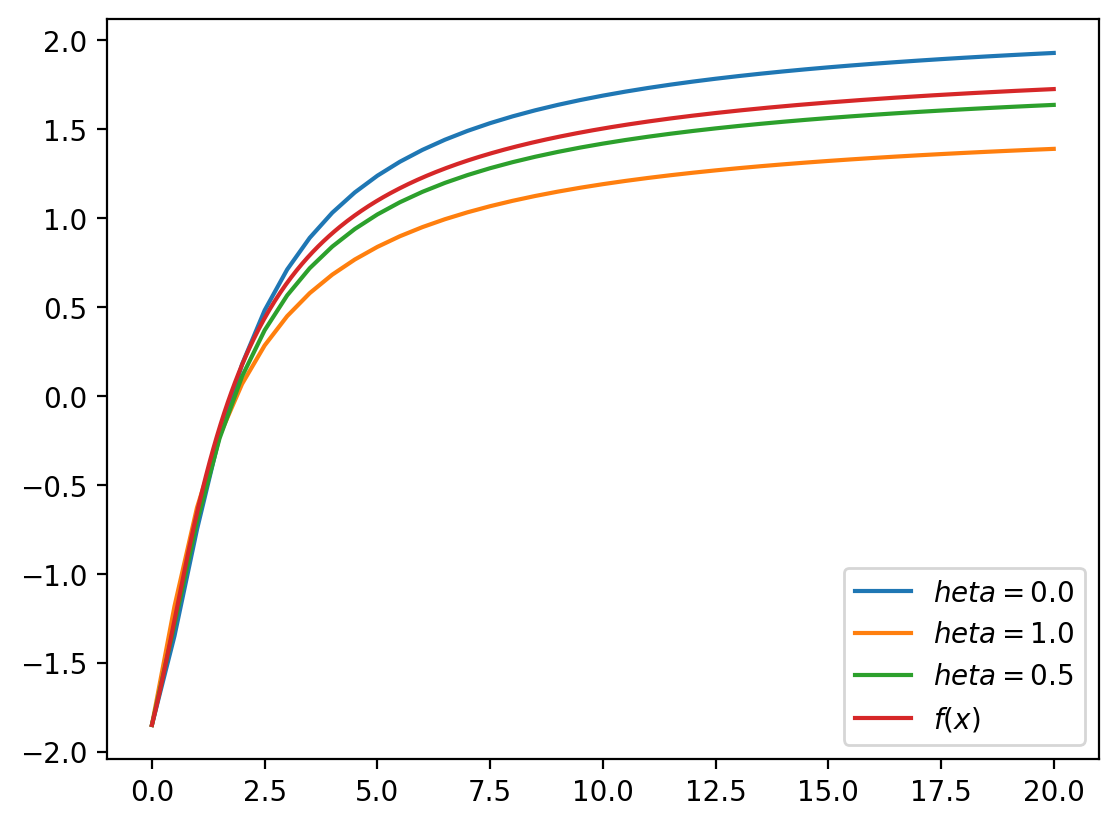

In [4]:
t0, tf, u0, N = 0, 20, 1-np.exp(np.pi/3), 40

theta=0
t1, u1 = thetaSchema(t0, tf, u0, N, theta)
plt.plot(t1, u1, label="$\theta ={:2.1f}$".format(theta))

theta=1
t2, u2 = thetaSchema(t0, tf, u0, N, theta)
plt.plot(t2, u2, label="$\theta ={:2.1f}$".format(theta))

theta=0.5
t3, u3 = thetaSchema(t0, tf, u0, N, theta)
plt.plot(t3, u3, label="$\theta ={:2.1f}$".format(theta))

t = np.linspace(t0, tf, 500)
plt.plot(t,x(t), label='$f(x)$')


plt.legend()
plt.show()

#### Question 2-2-3:  Ordre de convergence

Déterminer numériquement, l'ordre de convergence de la méthode pour les trois valeurs $\theta = 0$, 
$\theta = \frac12$, $\theta = 1$,

In [5]:
def analyse_erreur_schema_un_pas(t0, tf, x_exacte, theta, title):
    dts = (tf - t0)/(2.**np.arange(3,11))
    E = 0 * dts
    for i, dt in enumerate(dts):
        N = int( (tf - t0)/dt)
        t_, x_ = thetaSchema(t0, tf, x_exacte(t0), N, theta)
        xe = x_exacte(t_)
        E[i] = np.max(np.abs(xe - x_))
    fmt1 = "| {:^20s} | {:^20s} | {:^23s} |".format('dt', 'E_dt', "log(E_dt/E_{dt/2})/log(2)") 
    print('-'* len(fmt1))
    print(fmt1)
    print('-'* len(fmt1))
    fmt3 = "| {0:^20.2E} | {1:^20.4E} | {2:^23s} |"
    fmt2 = "| {0:^20.2E} | {1:^20.4E} | {2:^23.2f} |"
    print(fmt3.format(dts[0], E[0],'-'))
    for i in range(1, dts.size):
        print(fmt2.format(dts[i], E[i], np.log(E[i-1]/E[i])/np.log(2.) ))
    print('-'* len(fmt1))
    print("| {} \n| Estimation de l'ordre du Schéma {} pour EDO".format(title, theta))
    print('-'* len(fmt1))

In [6]:
t0, tf = 0, 20 
analyse_erreur_schema_un_pas(t0, tf, x, theta=0, title="Euler Explicite")

---------------------------------------------------------------------------
|          dt          |         E_dt         | log(E_dt/E_{dt/2})/log(2) |
---------------------------------------------------------------------------
|       2.50E+00       |      1.1379E+00      |            -            |
|       1.25E+00       |      4.6005E-01      |          1.31           |
|       6.25E-01       |      2.4566E-01      |          0.91           |
|       3.12E-01       |      1.3445E-01      |          0.87           |
|       1.56E-01       |      7.1068E-02      |          0.92           |
|       7.81E-02       |      3.6659E-02      |          0.96           |
|       3.91E-02       |      1.8636E-02      |          0.98           |
|       1.95E-02       |      9.3980E-03      |          0.99           |
---------------------------------------------------------------------------
| Euler Explicite 
| Estimation de l'ordre du Schéma 0 pour EDO
----------------------------------------

In [7]:
t0, tf = 0, 20 
analyse_erreur_schema_un_pas(t0, tf, x, theta=0.5, title="Cranc-Nicolson")

---------------------------------------------------------------------------
|          dt          |         E_dt         | log(E_dt/E_{dt/2})/log(2) |
---------------------------------------------------------------------------
|       2.50E+00       |      6.7162E-01      |            -            |
|       1.25E+00       |      4.6949E-01      |          0.52           |
|       6.25E-01       |      1.4018E-01      |          1.74           |
|       3.12E-01       |      3.4259E-02      |          2.03           |
|       1.56E-01       |      8.5034E-03      |          2.01           |
|       7.81E-02       |      2.1221E-03      |          2.00           |
|       3.91E-02       |      5.3028E-04      |          2.00           |
|       1.95E-02       |      1.3255E-04      |          2.00           |
---------------------------------------------------------------------------
| Cranc-Nicolson 
| Estimation de l'ordre du Schéma 0.5 pour EDO
---------------------------------------

In [8]:
t0, tf = 0, 20 
analyse_erreur_schema_un_pas(t0, tf, x, theta=1., title="Euler Implicite")

---------------------------------------------------------------------------
|          dt          |         E_dt         | log(E_dt/E_{dt/2})/log(2) |
---------------------------------------------------------------------------
|       2.50E+00       |      2.6886E+00      |            -            |
|       1.25E+00       |      1.5047E+00      |          0.84           |
|       6.25E-01       |      4.7644E-01      |          1.66           |
|       3.12E-01       |      1.8054E-01      |          1.40           |
|       1.56E-01       |      8.1989E-02      |          1.14           |
|       7.81E-02       |      3.9354E-02      |          1.06           |
|       3.91E-02       |      1.9307E-02      |          1.03           |
|       1.95E-02       |      9.5658E-03      |          1.01           |
---------------------------------------------------------------------------
| Euler Implicite 
| Estimation de l'ordre du Schéma 1.0 pour EDO
--------------------------------------

### Question 2-3: Applications

#### Question 2-3-1 
- Vérifier numériquement que la solution exacte de l'équation admet une unique racine dans l'intervalle $[0,5]$

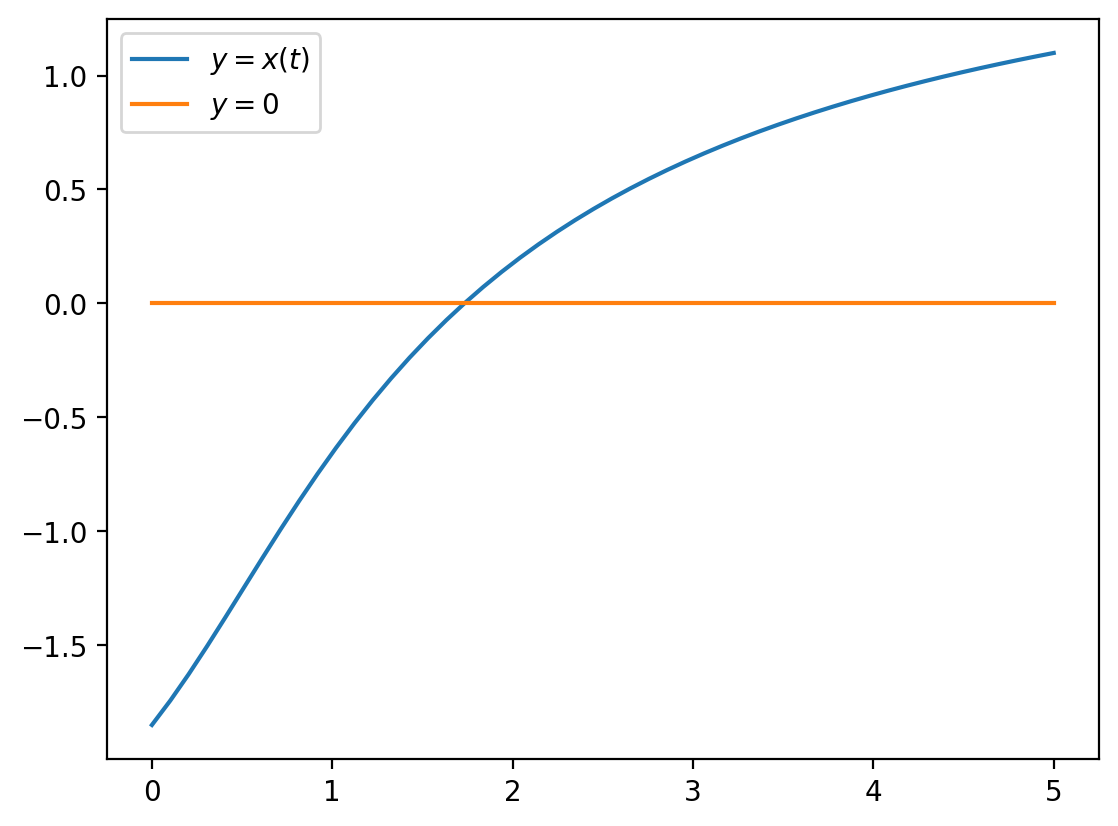

In [9]:
t = np.linspace(0,5,50)
plt.plot(t, x(t), label="$y=x(t)$")
plt.plot(t, 0*t, label="$y=0$")
plt.legend()
plt.show()

#### Question 2-3-2:

En utilisant la fonction `thetaSchema`,
expliquer comment déternimer l'unique  racine de x(t) solution de l'edo, avec `4 bons chiffres` décimaux.

**Indications**: *On pourra jouer sur la valeur du pas $\Delta t$ avec en vue le fait que pour un schéma numérique pour edo, convergent d'ordre $p$, on a l'estimation d'erreur : 
$\displaystyle \max_{0\leq n \leq N} |x(t_n) - x_n| \leq C_T (\Delta t)^p$, où $C_T > 0$ est une constante positive.* 

In [10]:
t0, tf, u0, N = 0, 2, 1-np.exp(np.pi/3), 20000

theta = 0.5  # on choisit le schéma qui converge à l"ordre 2  (i.e p = 2)

t2, u2 = thetaSchema(t0, tf, u0, N, theta)

# On cherche le premier indice i tel que u2[i] * u2[i+1] < 0
# Dès lors la valeur approchée de t* (telle que u(t*) = 0)  sera telle que t2[i] <  t*  < t2[i+1] 
# t* sera donc connue avec une marge d'erreur  | t2[i+1] - t2[i] |  si l'on prend t* = (t2[i+1] + t2[i])/2

i = 0
while u2[i] * u2[i+1] > 0:
    i += 1

# valeur approchée de t*    
t_start = (t2[i] + t2[i+1])/2

# Affichage et vérification
print("Valeur calculée:  t^* = ", t_start, ", Vérification:   x(t^*) = ",  x(t_start))

# Vérification de la soution exacte
print("Valeur exacte  :  t^* = ", np.sqrt(3), ", Vérification:   x(t^*) = ",  x(np.sqrt(3)))

# calcul de l'erreur
print("Erreur absolue : ",  np.abs(t_start - np.sqrt(3)))

# vérification du pas dt choisi  ( doit être ici 0.0001
print("dt,  utilisé   : ", (tf - t0)/N)


Valeur calculée:  t^* =  1.7320499999998256 , Vérification:   x(t^*) =  -5.75323219287327e-07
Valeur exacte  :  t^* =  1.7320508075688772 , Vérification:   x(t^*) =  0.0
Erreur absolue :  8.075690516307077e-07
dt,  utilisé   :  0.0001
